<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 11: CNN for Image Classification

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Implement a Convolutional Neural Network with 2D convolutions, max-pooling, and evaluate multiclass image representations.


### Task 1: Synthesize 2D Image Dataset (Synthetic Handwritten Shapes/Digits)


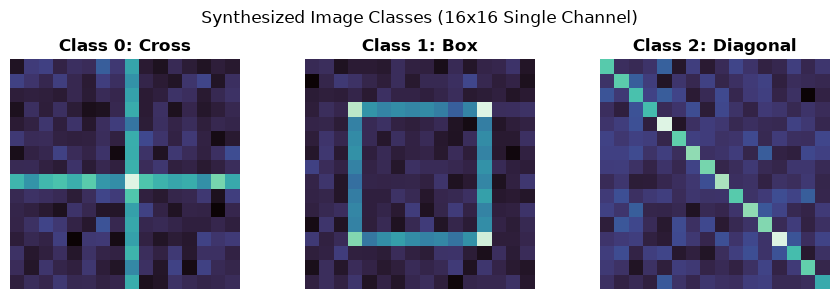

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix
import seaborn as sns

np.random.seed(42)
n_samples = 400
img_size = 16

# Generate 3 geometric shape classes: 0: Cross, 1: Box, 2: Diagonal Slash
X_imgs = np.zeros((n_samples, 1, img_size, img_size), dtype=np.float32)
y_imgs = np.random.randint(0, 3, size=n_samples)

for i in range(n_samples):
    img = np.random.normal(0, 0.15, (img_size, img_size))
    if y_imgs[i] == 0: # Cross
        img[img_size//2, :] += 1.0
        img[:, img_size//2] += 1.0
    elif y_imgs[i] == 1: # Box border
        img[3:13, 3] += 1.0
        img[3:13, 12] += 1.0
        img[3, 3:13] += 1.0
        img[12, 3:13] += 1.0
    else: # Diagonal
        np.fill_diagonal(img, img.diagonal() + 1.2)
    X_imgs[i, 0] = img

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
shape_names = ["Cross", "Box", "Diagonal"]
for k in range(3):
    idx = np.where(y_imgs == k)[0][0]
    axes[k].imshow(X_imgs[idx, 0], cmap='mako')
    axes[k].set_title(f"Class {k}: {shape_names[k]}", fontweight='bold')
    axes[k].axis('off')
plt.suptitle("Synthesized Image Classes (16x16 Single Channel)", fontsize=12)
plt.tight_layout()
plt.show()


### Task 2: Construct and Train Convolutional Neural Network (CNN)


In [2]:
# Train/Test Split
split = int(0.75 * n_samples)
X_train_img = torch.tensor(X_imgs[:split])
y_train_img = torch.tensor(y_imgs[:split], dtype=torch.long)
X_test_img = torch.tensor(X_imgs[split:])
y_test_img = torch.tensor(y_imgs[split:], dtype=torch.long)

class ConvClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 16x16 -> 8x8
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 8x8 -> 4x4
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 32),
            nn.ReLU(),
            nn.Linear(32, 3)
        )
    def forward(self, x):
        return self.fc(self.features(x))

cnn = ConvClassifier()
opt = optim.Adam(cnn.parameters(), lr=0.008)
loss_fn = nn.CrossEntropyLoss()

train_losses = []
for ep in range(40):
    cnn.train()
    opt.zero_grad()
    logits = cnn(X_train_img)
    l = loss_fn(logits, y_train_img)
    l.backward()
    opt.step()
    train_losses.append(l.item())

cnn.eval()
with torch.no_grad():
    test_logits = cnn(X_test_img)
    preds = torch.argmax(test_logits, dim=1).numpy()
    test_acc = np.mean(preds == y_test_img.numpy()) * 100

print(f"CNN Final Training Loss: {train_losses[-1]:.4f} | Test Accuracy: {test_acc:.2f}%")


CNN Final Training Loss: 0.0000 | Test Accuracy: 100.00%


### Task 3: Test Confusion Matrix and Feature Map Visualization


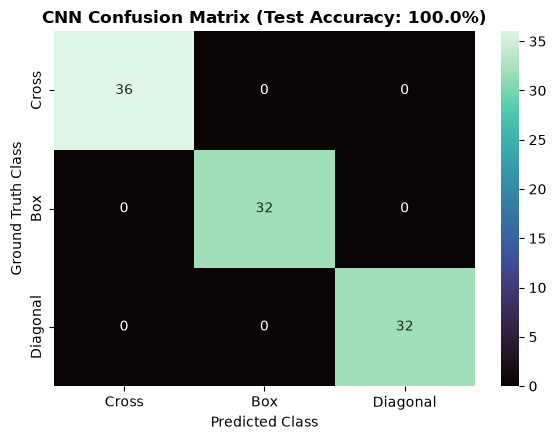

In [3]:
cm = confusion_matrix(y_test_img.numpy(), preds)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='mako',
            xticklabels=shape_names, yticklabels=shape_names)
plt.title(f"CNN Confusion Matrix (Test Accuracy: {test_acc:.1f}%)", fontweight='bold')
plt.xlabel("Predicted Class")
plt.ylabel("Ground Truth Class")
plt.tight_layout()
plt.show()
